# 01 - Analyse exploratoire (section 2.1)

Dans ce notebook l'objectif est de décrire les données, vérifier leur qualité, analyser la distribution et le déséquilibre des classes, et observer les relations entre les differentes variables.

**Cible binaire :** `bon = 1` si `quality >= 7`.

In [1]:
import sys
from pathlib import Path

# Fonctionne qu'on lance le notebook depuis notebooks/ ou depuis la racine du projet
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

from src.load_data import DATA_DIR, RED_FILE, WHITE_FILE, load_wine_data, make_binary_target

print("Dossier des données :", DATA_DIR.resolve())

Dossier des données : /Users/cam/WineQuality/data/raw


## 1. Chargement et vérification des sources

In [2]:
for name in (RED_FILE, WHITE_FILE):
    print(f"{name:25s} présent : {(DATA_DIR / name).exists()}")

df = make_binary_target(load_wine_data())
print("\nDimensions après fusion :", df.shape)
df.head()

winequality-red.csv       présent : True
winequality-white.csv     présent : True

Dimensions après fusion : (6497, 14)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type,bon
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,rouge,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,rouge,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,rouge,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge,0


## 2. Statistiques descriptives

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
 13  bon                   6497 non-null   int64  
dtypes: float64(11), int64(2), str(1)
memory usage: 710.7 KB


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


## 3. Valeurs manquantes et doublons

In [5]:
print("Valeurs manquantes au total :", int(df.isna().sum().sum()))
print("Doublons exacts             :", int(df.duplicated().sum()))
print()
print("Doublons par type de vin :")
print(df.assign(dup=df.duplicated()).groupby("type")["dup"].sum())

Valeurs manquantes au total : 0
Doublons exacts             : 1177

Doublons par type de vin :
type
blanc    937
rouge    240
Name: dup, dtype: int64


**À compléter :** nombre de doublons, répartition rouge/blanc, et traitement retenu (suppression dans `clean_data`, au notebook 02).

## 4. Distribution des classes et déséquilibre

Effectifs par note de qualité :
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


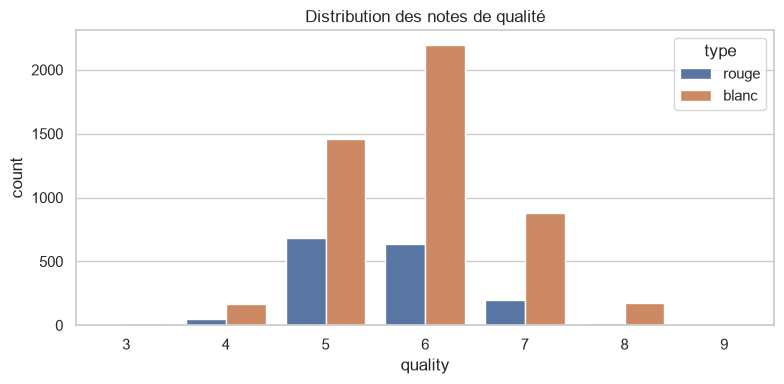

In [6]:
print("Effectifs par note de qualité :")
print(df["quality"].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x="quality", hue="type", data=df, ax=ax)
ax.set_title("Distribution des notes de qualité")
plt.tight_layout()
plt.show()

In [7]:
counts = df["bon"].value_counts().sort_index()
n_moins_bon, n_bon = int(counts.loc[0]), int(counts.loc[1])

print("Effectifs (0 = moins bon, 1 = bon) :", {0: n_moins_bon, 1: n_bon})
print("Proportion de bons vins            :", round(n_bon / len(df), 3))
print("Ratio moins bon / bon             :", round(n_moins_bon / n_bon, 2))
print()
print("Proportion de bons vins par type :")
print(df.groupby("type")["bon"].mean().round(3))

Effectifs (0 = moins bon, 1 = bon) : {0: 5220, 1: 1277}
Proportion de bons vins            : 0.197
Ratio moins bon / bon             : 4.09

Proportion de bons vins par type :
type
blanc    0.216
rouge    0.136
Name: bon, dtype: float64


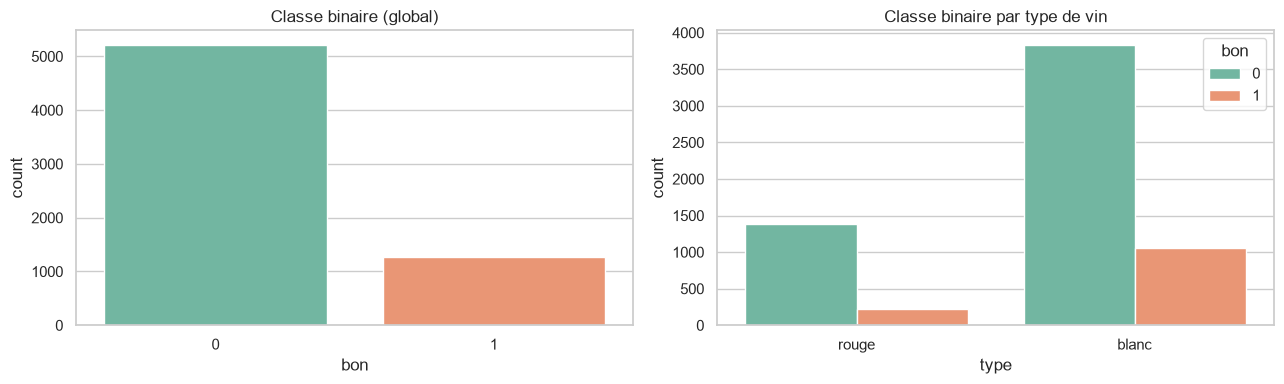

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x="bon", data=df, ax=axes[0], hue="bon", legend=False, palette="Set2")
axes[0].set_title("Classe binaire (global)")
sns.countplot(x="type", hue="bon", data=df, ax=axes[1], palette="Set2")
axes[1].set_title("Classe binaire par type de vin")
plt.tight_layout()
plt.show()

**À compléter :** commentez le ratio de déséquilibre. Quelles conséquences pour le choix des métriques (accuracy seule trompeuse, intérêt du rappel, du F1 et de l'AUC) ? Les vins blancs sont-ils plus souvent « bons » que les rouges ?

## 5. Histogrammes des variables

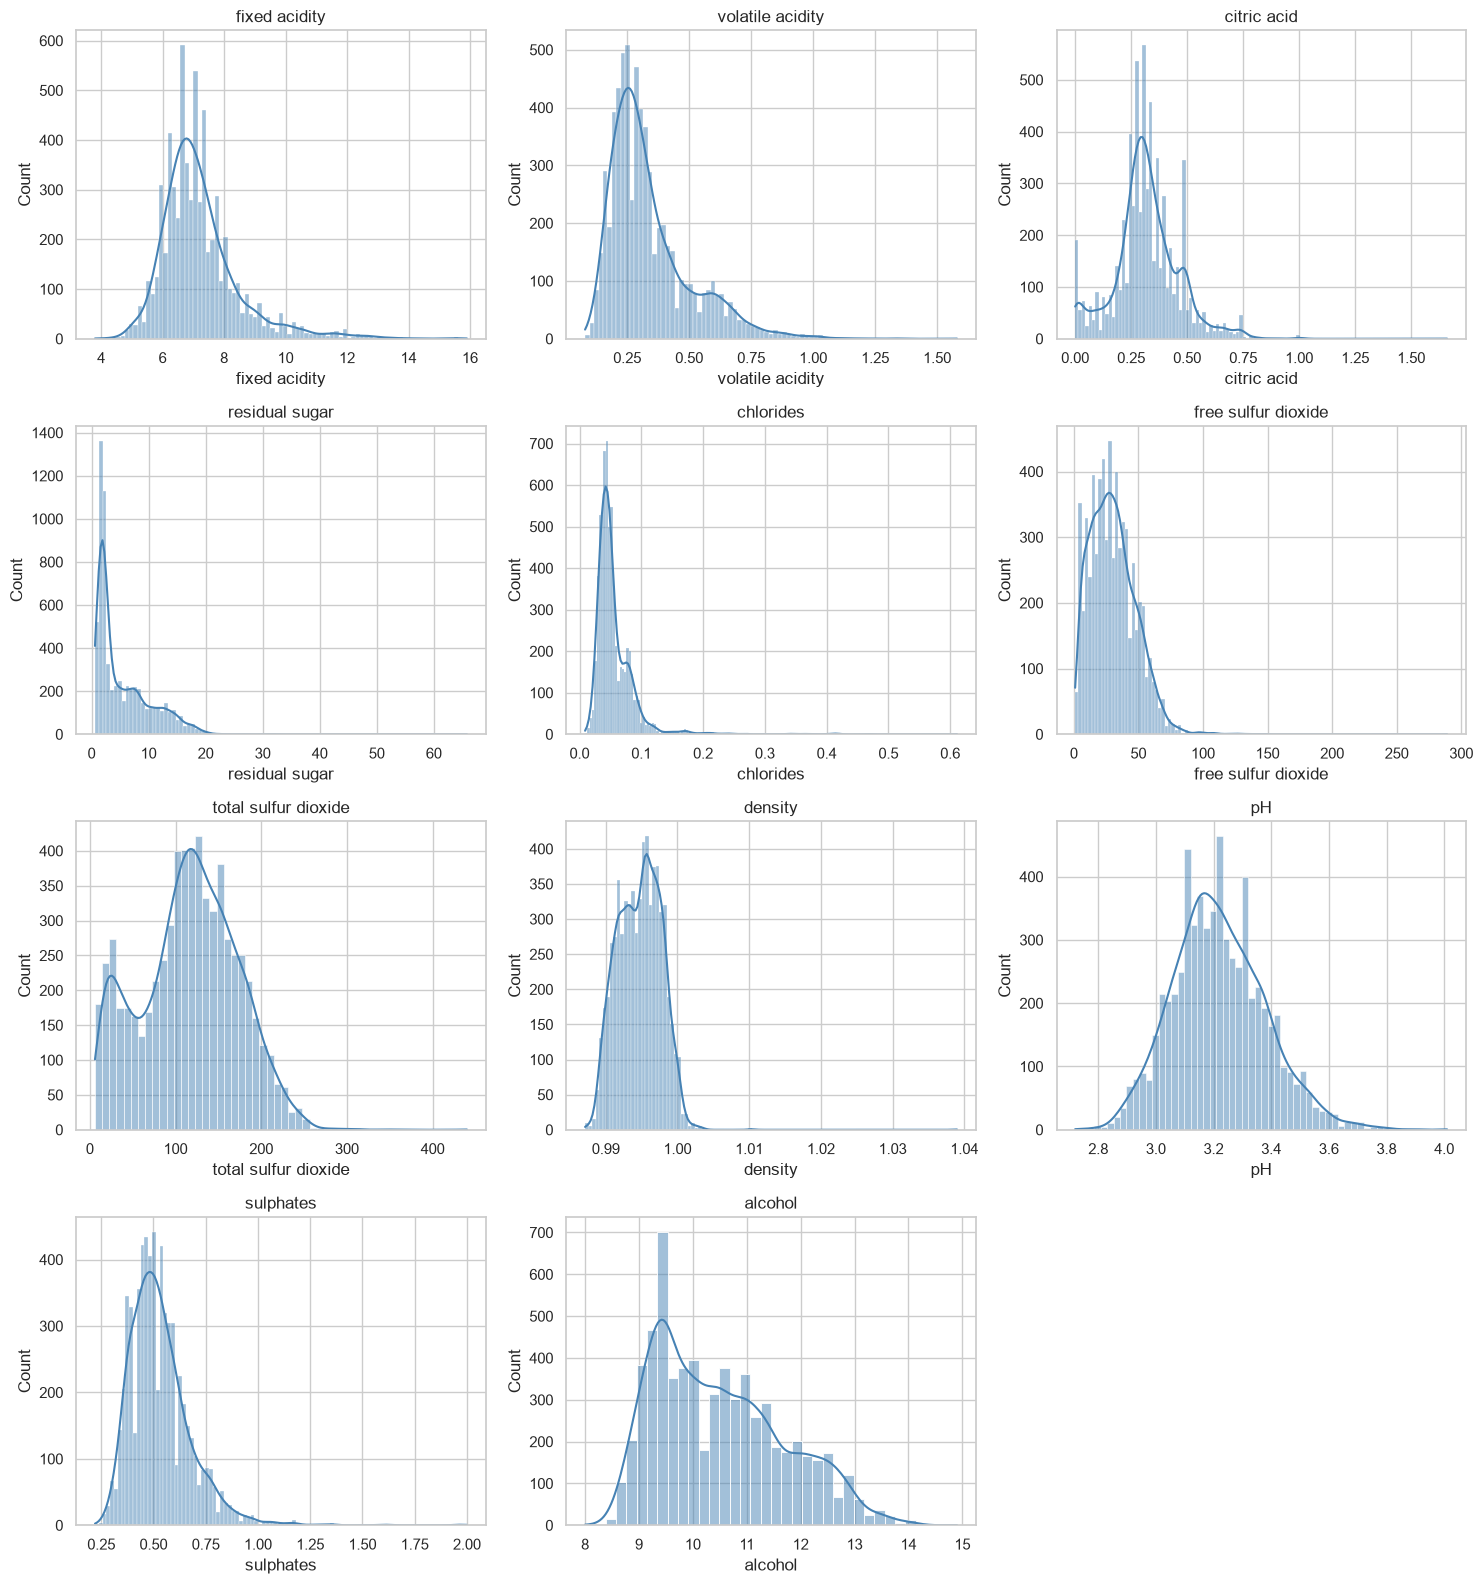

In [9]:
features = [c for c in df.columns if c not in ["type", "quality", "bon"]]

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
for ax in list(axes.flat)[len(features):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**À compléter :** variables asymétriques (queue à droite), variables proches d'une loi normale.

## 6. Valeurs aberrantes (méthode IQR)

Les valeurs aberrantes sont signalées, pas supprimées. Le pipeline les plafonnera (`IQRClipper`), ajusté sur le train uniquement.

In [10]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in features:
    lo, hi = iqr_bounds(df[col])
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    rows.append({
        "variable": col,
        "borne_basse": lo,
        "borne_haute": hi,
        "n_aberrantes": n_out,
        "pourcentage": 100 * n_out / len(df),
    })

outliers = pd.DataFrame(rows).sort_values("pourcentage", ascending=False)
outliers.round(2)

,variable,borne_basse,borne_haute,n_aberrantes,pourcentage
2,citric acid,0.04,0.60,509,7.83
1,volatile acidity,-0.02,0.66,377,5.80
0,fixed acidity,4.45,9.65,357,5.49
4,chlorides,-0.00,0.11,286,4.40
9,sulphates,0.18,0.86,191,2.94
3,residual sugar,-7.65,17.55,118,1.82
8,pH,2.80,3.64,73,1.12
5,free sulfur dioxide,-19.00,77.00,62,0.95
6,total sulfur dioxide,-41.50,274.50,10,0.15
7,density,0.99,1.00,3,0.05


## 7. Boxplots par classe

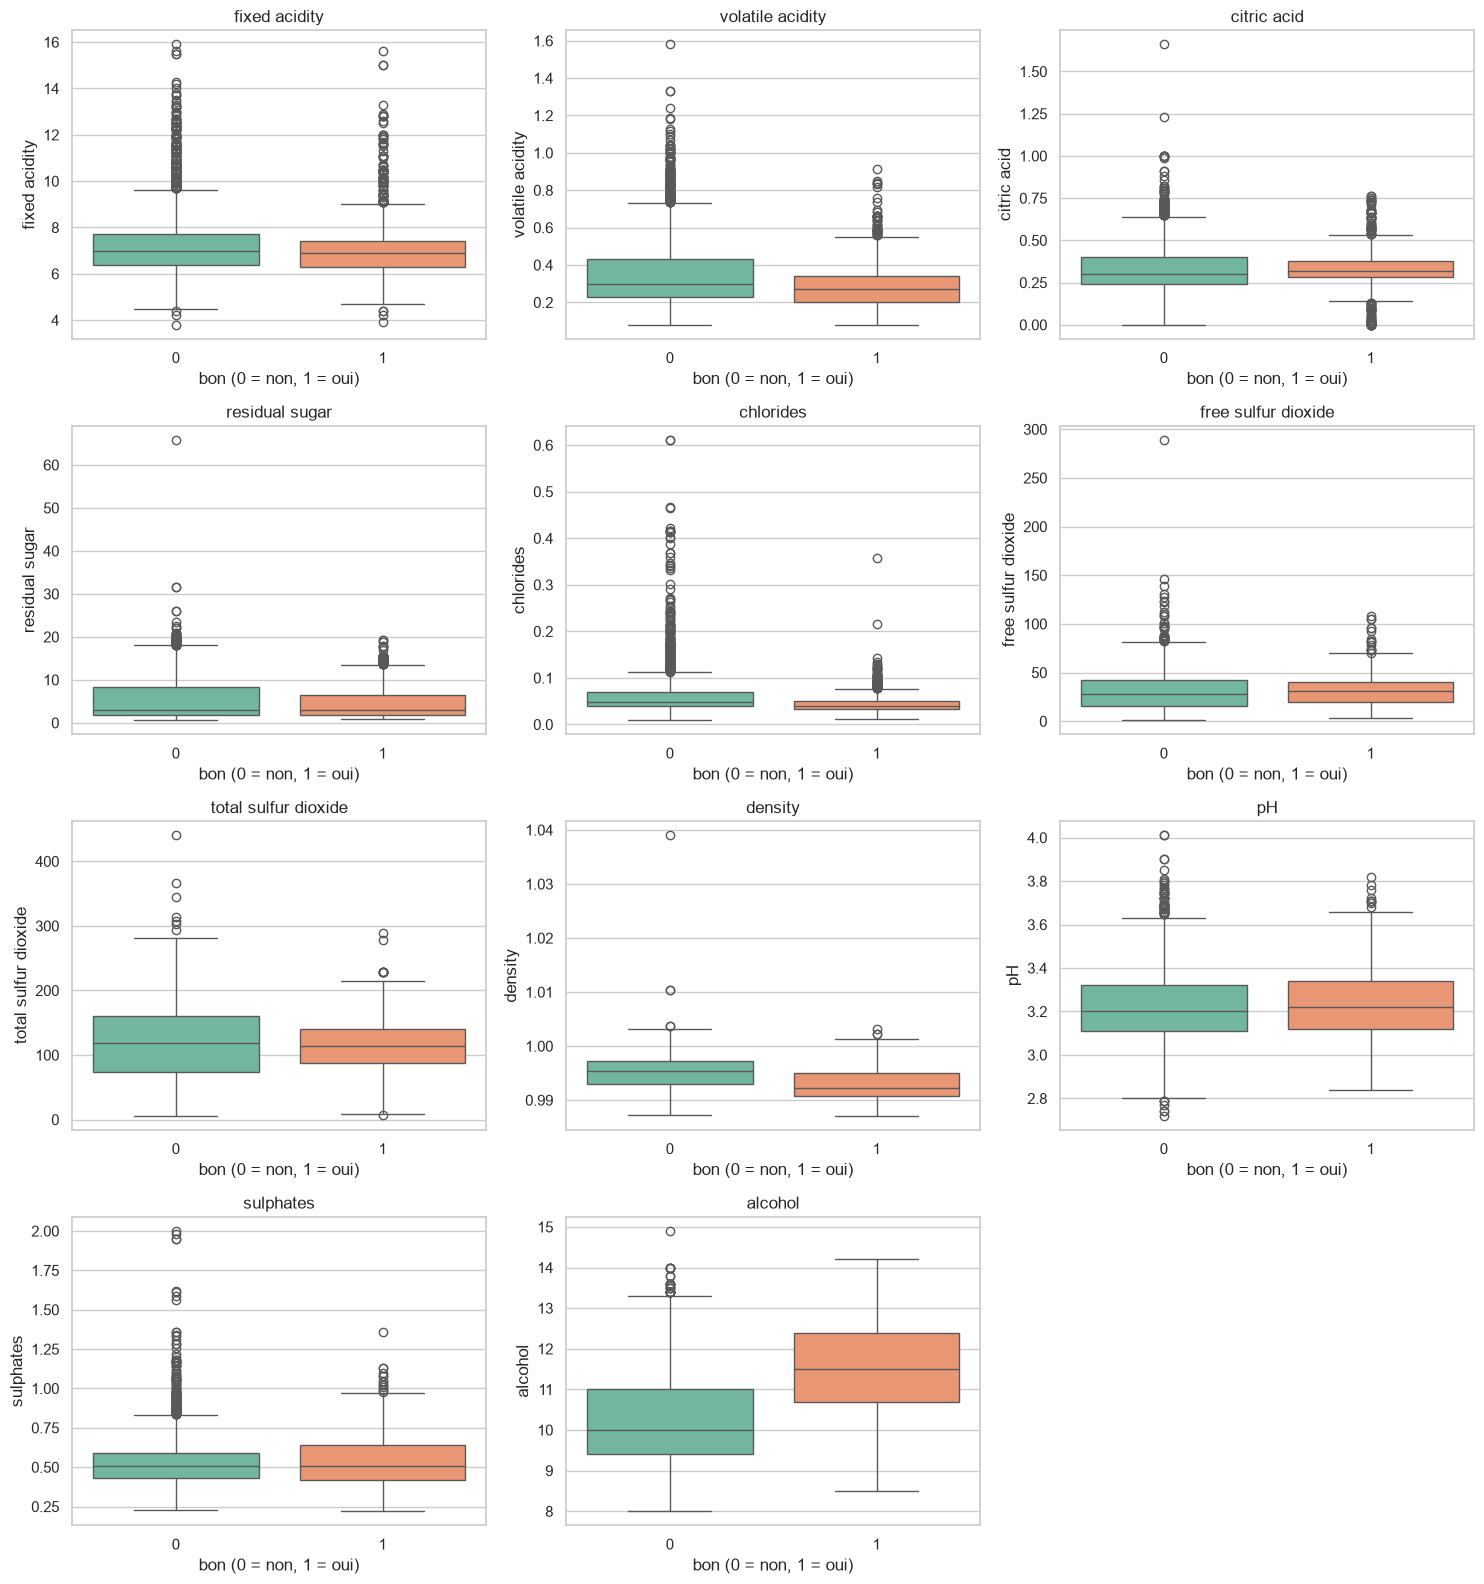

In [11]:
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, col in zip(axes.flat, features):
    sns.boxplot(x="bon", y=col, data=df, ax=ax, hue="bon", legend=False, palette="Set2")
    ax.set_title(col)
    ax.set_xlabel("bon (0 = non, 1 = oui)")
for ax in list(axes.flat)[len(features):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**À compléter :** variables qui séparent le plus les deux classes.

## 8. Matrice de corrélation

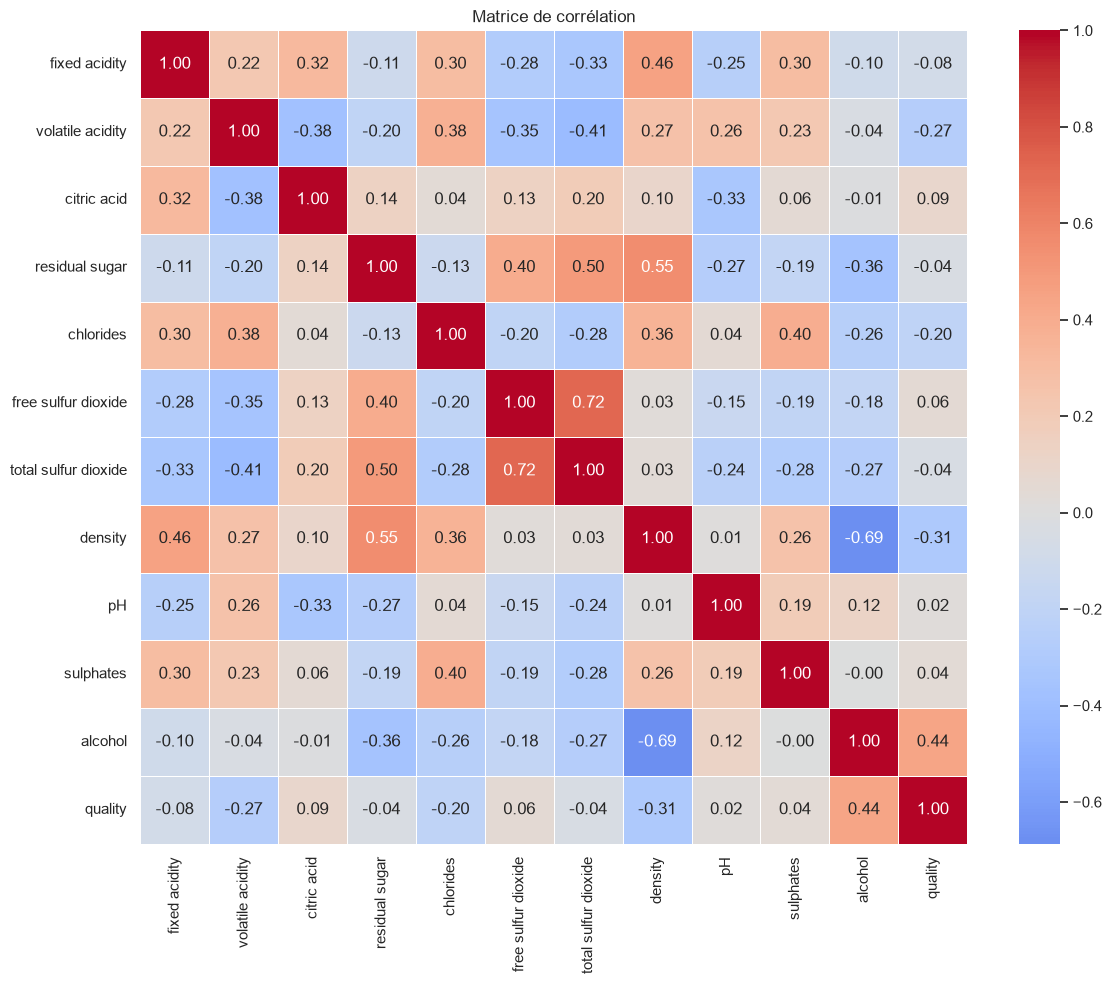

In [12]:
corr = df[features + ["quality"]].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

In [13]:
print("Corrélation avec la qualité (triées par valeur absolue) :")
corr["quality"].drop("quality").sort_values(key=abs, ascending=False).round(3)

Corrélation avec la qualité (triées par valeur absolue) :


alcohol                 0.444
density                -0.306
volatile acidity       -0.266
chlorides              -0.201
citric acid             0.086
fixed acidity          -0.077
free sulfur dioxide     0.055
total sulfur dioxide   -0.041
sulphates               0.038
residual sugar         -0.037
pH                      0.020
Name: quality, dtype: float64

In [14]:
# Paires de variables fortement corrélées entre elles (|r| > 0.6)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().reset_index()
pairs.columns = ["var_1", "var_2", "r"]
pairs[pairs["r"].abs() > 0.6].sort_values("r", key=abs, ascending=False)

,var_1,var_2,r
66,free sulfur dioxide,total sulfur dioxide,0.720934
94,density,alcohol,-0.686745


**À compléter :** paires redondantes (par exemple `free sulfur dioxide` / `total sulfur dioxide`, ou `density` avec `alcohol` ou `residual sugar`). Pourquoi cela pose-t-il problème pour certains modèles ?

## 9. Synthèse de la section 2.1

- Déséquilibre des classes (ratio et conséquences) :
- Valeurs manquantes et doublons :
- Valeurs aberrantes (à plafonner) :
- Variables les plus liées à la cible :
- Paires de variables redondantes :
- Transformations envisagées (log, etc.) :